# Random forest: daily high temperature, leads 1 to 7

Danylo Huk, `random-forest` branch.

One `RandomForestRegressor` per lead time, trained on 2000-2019 and scored with the shared `score()`
on the validation years (2020-2022), against the damped anomaly forecast. The test years
(2023-2025) are not touched here.

Steps:
1. Build features from data through day t (the forecast day).
2. Tune on a 300,000-row sample of the training rows, comparing settings on validation MAE at leads 1 and 7.
3. Refit the winning setting on all training rows for each lead and score leads 1 to 7.
4. Permutation feature importance at leads 1 and 7.

Results tables and charts are written to `notebooks/random_forest_results/`.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

sys.path.insert(0, "../data_scripts")  # relative to the notebook's folder
from prepare_data import load_data, STATIONS
from scoring import simple_forecasts, score, climatology, LEADS, TARGETS

OUT = Path("random_forest_results")
OUT.mkdir(exist_ok=True)
SEED = 0
N_JOBS = -1
RERUN_TUNING = False  # tuning results are cached in random_forest_results/tuning.csv

data = load_data()
print(f"{data.STATION.nunique()} stations, {len(data):,} station-days")
print(data[data.usable].period.value_counts().to_string())

280 stations, 2,659,160 station-days
period
train         1825364
validation     282981
test           270013


## Features

Every feature uses only data through day t, the forecast day:

* **Today and recent days at the station:** TMAX today and 1-6 days back, TMIN today and yesterday,
  7- and 30-day mean TMAX, the change since yesterday.
* **Departure from normal:** the station's climatology (from `scoring.climatology`, fitted on training
  years only) today and on the target day, today's anomaly and its 3- and 7-day mean.
* **Other weather:** precipitation today and over 7 days, snow depth, average wind (only some stations report it).
* **Neighbours:** today's mean anomaly at the 5 nearest stations, at stations to the west and to the north
  (within 500 km), and across all stations, plus how the statewide anomaly changed since yesterday.
  Weather systems in Texas mostly arrive from the west and north, so these help at longer leads.
* **Place and season:** latitude, longitude, elevation, day of year as sine and cosine.

Missing values are left as NaN: scikit-learn's random forest handles them natively.

The model predicts the target day's **departure from climatology** (`y_h` minus climatology on day t+h), and
climatology is added back. Section 2 also compares this with predicting TMAX directly.

In [2]:
t0 = time.time()
stations = pd.read_csv(STATIONS).set_index("ID")
usual = climatology(data)
clim_today = usual(data.STATION, data.DATE).astype("float32")
anom = (data.TMAX - clim_today).astype("float32")

g = data.groupby("STATION", sort=False)
roll = lambda col, n, k, how="mean": g[col].transform(lambda s: getattr(s.rolling(n, min_periods=k), how)())

F = pd.DataFrame(index=data.index)
F["tmax"] = data.TMAX
for k in range(1, 7):
    F[f"tmax_lag{k}"] = g.TMAX.shift(k)
F["tmax_change1"] = data.TMAX - F.tmax_lag1
F["tmax_mean7"] = roll("TMAX", 7, 4)
F["tmax_mean30"] = roll("TMAX", 30, 20)
F["tmin"] = data.TMIN
F["tmin_lag1"] = g.TMIN.shift(1)
F["clim_today"] = clim_today
F["anom"] = anom
anom_g = anom.groupby(data.STATION, sort=False)
F["anom_mean3"] = anom_g.transform(lambda s: s.rolling(3, min_periods=2).mean())
F["anom_mean7"] = anom_g.transform(lambda s: s.rolling(7, min_periods=4).mean())
F["prcp"] = data.PRCP
F["prcp_sum7"] = roll("PRCP", 7, 4, "sum")
F["snwd"] = data.SNWD
F["awnd"] = data.AWND

# Neighbour anomalies: a date x station matrix of today's anomaly, averaged over each station's neighbours.
A = anom.groupby([data.DATE, data.STATION]).first().unstack()
loc = stations.loc[A.columns]
lat, lon = loc.LATITUDE.to_numpy(), loc.LONGITUDE.to_numpy()
la, lo = np.radians(lat), np.radians(lon)
h = (np.sin((la[:, None] - la[None, :]) / 2) ** 2
     + np.cos(la[:, None]) * np.cos(la[None, :]) * np.sin((lo[:, None] - lo[None, :]) / 2) ** 2)
dist = 2 * 6371 * np.arcsin(np.sqrt(h))  # km
np.fill_diagonal(dist, np.inf)
nearest = np.zeros_like(dist)
nearest[np.arange(len(dist))[:, None], np.argsort(dist, axis=1)[:, :5]] = 1
west = ((lon[None, :] < lon[:, None] - 1) & (dist < 500)).astype(float)   # row: station, column: its neighbours
north = ((lat[None, :] > lat[:, None] + 1) & (dist < 500)).astype(float)

values, seen = A.fillna(0).to_numpy(), A.notna().to_numpy().astype(float)
def neighbour_mean(W):
    with np.errstate(invalid="ignore", divide="ignore"):
        return (values @ W.T) / (seen @ W.T)

rows_date = A.index.get_indexer(data.DATE)
rows_station = A.columns.get_indexer(data.STATION)
for name, W in [("nbr5_anom", nearest), ("west_anom", west), ("north_anom", north)]:
    F[name] = neighbour_mean(W)[rows_date, rows_station]
state = A.mean(axis=1)
F["state_anom"] = state.to_numpy()[rows_date]
F["state_anom_change1"] = state.diff().to_numpy()[rows_date]

F["latitude"] = data.STATION.map(stations.LATITUDE).to_numpy()
F["longitude"] = data.STATION.map(stations.LONGITUDE).to_numpy()
F["elevation"] = data.STATION.map(stations.ELEVATION).to_numpy()
doy = 2 * np.pi * data.DATE.dt.dayofyear / 365.25
F["doy_sin"], F["doy_cos"] = np.sin(doy), np.cos(doy)

F = F.astype("float32")
FEATURES = list(F.columns) + ["clim_target"]
print(f"{len(FEATURES)} features, built in {time.time() - t0:.0f} s")
print(f"stations with no west neighbour: {(west.sum(1) == 0).sum()}, no north neighbour: {(north.sum(1) == 0).sum()}")

X_base = F.to_numpy()
clim_target = {h: usual(data.STATION, data.DATE + pd.Timedelta(days=h)).astype("float32") for h in LEADS}
def features(h, pos):
    # The lead-specific column: climatology on the target day.
    return np.column_stack([X_base[pos], clim_target[h][pos]])

train_pos = np.flatnonzero(data.usable & (data.period == "train"))
val_pos = np.flatnonzero(data.usable & (data.period == "validation"))
val_rows = data.iloc[val_pos]
print(f"training rows: {len(train_pos):,}, validation rows: {len(val_pos):,}")

C:\Users\gukda\AppData\Local\Temp\ipykernel_1396\2121562035.py:59: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  doy = 2 * np.pi * data.DATE.dt.dayofyear / 365.25


31 features, built in 3 s
stations with no west neighbour: 4, no north neighbour: 17


training rows: 1,825,364, validation rows: 282,981


## 1. Simple forecasts on validation

In [3]:
simple = simple_forecasts(data, val_rows)
baseline = {name: score(val_rows, f) for name, f in simple.items()}
pd.concat({name: s.MAE for name, s in baseline.items()}, axis=1).round(2)

,persistence,climatology,damped anomaly
lead time,,,
1,3.10,3.92,2.95
2,4.23,3.92,3.64
3,4.69,3.92,3.81
4,4.91,3.92,3.86
5,5.01,3.93,3.89
6,5.12,3.93,3.90
7,5.15,3.93,3.91


## 2. Tuning

Every setting is trained on the same random 300,000 training rows and scored on all validation rows at
leads 1 and 7 (the easiest and hardest lead); the setting with the lowest mean MAE over the two wins.
The search goes in stages, keeping the best setting from each stage:

1. `max_depth` (10, 20, unlimited) x `min_samples_leaf` (5, 20, 50), with 100 trees and `max_features=0.33`
2. `max_features`: 0.2, 0.33, 0.6, 1.0 (1.0 means plain bagging)
3. `n_estimators`: 50, 100, 300
4. Target: departure from climatology vs raw TMAX

`min_samples_leaf=1` was left out: on 1.7 million noisy rows, fully grown trees need tens of GB.

In [4]:
rng = np.random.default_rng(SEED)
tune_pos = np.sort(rng.choice(train_pos, 300_000, replace=False))
TUNE_LEADS = (1, 7)

def fit(params, h, pos, target="anomaly", **extra):
    y = data[f"y{h}"].to_numpy(np.float32)[pos]
    if target == "anomaly":
        y = y - clim_target[h][pos]
    model = RandomForestRegressor(**params, **extra, n_jobs=N_JOBS, random_state=SEED)
    return model.fit(features(h, pos), y)

def predict(model, h, pos, target="anomaly"):
    p = model.predict(features(h, pos))
    return p + clim_target[h][pos] if target == "anomaly" else p

cache = OUT / "tuning.csv"
done = pd.read_csv(cache) if cache.exists() and not RERUN_TUNING else pd.DataFrame()
records = done.to_dict("records")

def key(params, target):
    return f"trees={params['n_estimators']} depth={params['max_depth']} leaf={params['min_samples_leaf']} features={params['max_features']} target={target}"

def evaluate(params, stage, target="anomaly"):
    k = key(params, target)
    if not any(r["setting"] == k for r in records):
        row = {"stage": stage, "setting": k, **params, "target": target}
        t0 = time.time()
        for h in TUNE_LEADS:
            model = fit(params, h, tune_pos, target)
            err = predict(model, h, val_pos, target) - val_rows[f"y{h}"].to_numpy()
            row[f"MAE lead {h}"] = np.abs(err).mean()
            del model
        row["mean MAE"] = np.mean([row[f"MAE lead {h}"] for h in TUNE_LEADS])
        row["seconds"] = round(time.time() - t0)
        records.append(row)
        pd.DataFrame(records).to_csv(cache, index=False)
        print(f"{k}: {row['mean MAE']:.3f} ({row['seconds']} s)", flush=True)
    return next(r for r in records if r["setting"] == k)["mean MAE"]

def best(candidates, stage, target="anomaly"):
    scores = [evaluate(p, stage, target) for p in candidates]
    return candidates[int(np.argmin(scores))]

base = dict(n_estimators=100, max_depth=None, min_samples_leaf=5, max_features=0.33)
p = best([dict(base, max_depth=d, min_samples_leaf=l) for d in (10, 20, None) for l in (5, 20, 50)], "1 depth x leaf")
p = best([dict(p, max_features=f) for f in (0.2, 0.33, 0.6, 1.0)], "2 max_features")
p = best([dict(p, n_estimators=n) for n in (50, 100, 300)], "3 n_estimators")
raw = evaluate(p, "4 target", target="raw")
TARGET = "anomaly" if evaluate(p, "4 target") <= raw else "raw"
BEST = p
print("winner:", key(BEST, TARGET))

winner: trees=100 depth=20 leaf=50 features=0.2 target=anomaly


In [5]:
tuning = pd.DataFrame(records)
tuning["max_depth"] = tuning.max_depth.map(lambda d: "None" if pd.isna(d) else str(int(d)))
cols = ["stage", "n_estimators", "max_depth", "min_samples_leaf", "max_features", "target",
        "MAE lead 1", "MAE lead 7", "mean MAE", "seconds"]
tuning = tuning[cols].round(3)
tuning["winner"] = np.where(tuning.index == tuning["mean MAE"].idxmin(), "<- best", "")
tuning.to_csv(OUT / "tuning_table.csv", index=False)
tuning

,stage,n_estimators,max_depth,min_samples_leaf,max_features,target,MAE lead 1,MAE lead 7,mean MAE,seconds,winner
0,1 depth x leaf,100,10,5,0.33,anomaly,2.555,3.877,3.216,16,
1,1 depth x leaf,100,10,20,0.33,anomaly,2.550,3.872,3.211,16,
2,1 depth x leaf,100,10,50,0.33,anomaly,2.551,3.872,3.211,16,
3,1 depth x leaf,100,20,5,0.33,anomaly,2.513,3.909,3.211,24,
4,1 depth x leaf,100,20,20,0.33,anomaly,2.507,3.899,3.203,22,
5,1 depth x leaf,100,20,50,0.33,anomaly,2.515,3.886,3.200,21,
6,1 depth x leaf,100,None,5,0.33,anomaly,2.517,3.921,3.219,28,
7,1 depth x leaf,100,None,20,0.33,anomaly,2.510,3.900,3.205,24,
8,1 depth x leaf,100,None,50,0.33,anomaly,2.514,3.892,3.203,22,
9,2 max_features,100,20,50,0.20,anomaly,2.531,3.867,3.199,13,<- best


## 3. Final models, leads 1 to 7

The winning setting is refit on all training rows for each lead. Each tree is grown on a bootstrap sample of
500,000 rows (`max_samples`) rather than all 1.7 million, which keeps the 7 forests within memory and close to
the sample size the setting was tuned on.

In [6]:
pred = np.zeros((len(val_pos), len(TARGETS)))
importance = {}
impurity = {}
imp_rng = np.random.default_rng(SEED)
imp_pos = np.sort(imp_rng.choice(len(val_pos), 50_000, replace=False))

for i, h in enumerate(LEADS):
    t0 = time.time()
    model = fit(BEST, h, train_pos, TARGET, max_samples=500_000)
    pred[:, i] = predict(model, h, val_pos, TARGET)
    impurity[h] = pd.Series(model.feature_importances_, index=FEATURES)
    if h in (1, 7):
        # Permutation importance on 50,000 validation rows: how much MAE rises when a feature is shuffled.
        Xv = features(h, val_pos[imp_pos])
        yv = val_rows[f"y{h}"].to_numpy()[imp_pos]
        if TARGET == "anomaly":
            yv = yv - clim_target[h][val_pos[imp_pos]]
        r = permutation_importance(model, Xv, yv, scoring="neg_mean_absolute_error",
                                   n_repeats=3, random_state=SEED, n_jobs=1)
        importance[h] = pd.Series(r.importances_mean, index=FEATURES)
    del model
    print(f"lead {h}: {time.time() - t0:.0f} s", flush=True)

np.save(OUT / "validation_predictions.npy", pred)

lead 1: 28 s


lead 2: 24 s


lead 3: 25 s


lead 4: 24 s


lead 5: 26 s


lead 6: 30 s


lead 7: 34 s


In [7]:
rf = score(val_rows, pred)
damped = baseline["damped anomaly"]
results = pd.DataFrame({
    "RF MAE": rf.MAE, "RF RMSE": rf.RMSE,
    "Damped anomaly MAE": damped.MAE, "Damped anomaly RMSE": damped.RMSE,
    "MAE gain": damped.MAE - rf.MAE,
    "MAE gain %": 100 * (damped.MAE - rf.MAE) / damped.MAE,
}).round(2)
results.to_csv(OUT / "validation_results.csv")
print("Winning setting:", key(BEST, TARGET))
results

Winning setting: trees=100 depth=20 leaf=50 features=0.2 target=anomaly


,RF MAE,RF RMSE,Damped anomaly MAE,Damped anomaly RMSE,MAE gain,MAE gain %
lead time,,,,,,
1,2.52,3.56,2.95,4.09,0.43,14.55
2,3.42,4.69,3.64,4.90,0.22,6.04
3,3.72,5.05,3.81,5.11,0.09,2.40
4,3.82,5.16,3.86,5.17,0.04,1.11
5,3.88,5.26,3.89,5.21,0.01,0.21
6,3.88,5.26,3.90,5.23,0.03,0.67
7,3.88,5.28,3.91,5.24,0.03,0.64


## 4. Charts

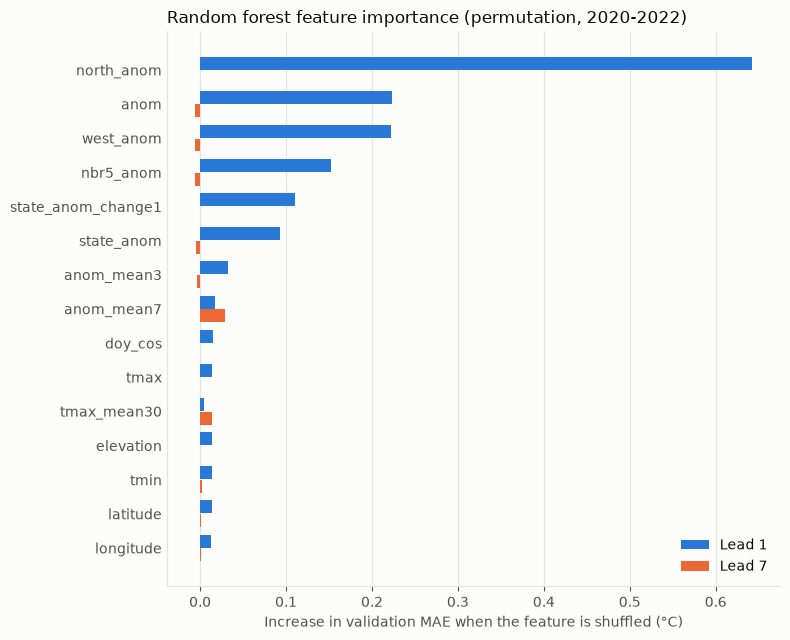

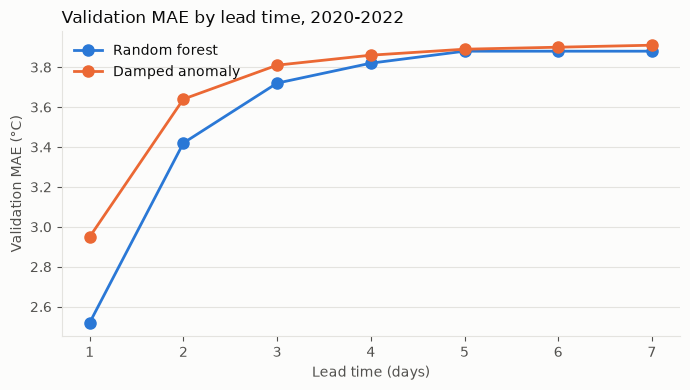

In [8]:
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

# Permutation importance, lead 1 vs lead 7: the 15 most important features at either lead.
imp = pd.DataFrame({"Lead 1": importance[1], "Lead 7": importance[7]})
top = imp.max(axis=1).sort_values(ascending=False).index[:15][::-1]
imp = imp.loc[top]
fig, ax = plt.subplots(figsize=(8, 6.5))
y = np.arange(len(imp))
bh = 0.38
ax.barh(y + bh / 2 + 0.01, imp["Lead 1"], height=bh, color=BLUE, label="Lead 1")
ax.barh(y - bh / 2 - 0.01, imp["Lead 7"], height=bh, color=ORANGE, label="Lead 7")
ax.set_yticks(y, imp.index)
ax.set_xlabel("Increase in validation MAE when the feature is shuffled (°C)")
ax.set_title("Random forest feature importance (permutation, 2020-2022)", loc="left", color=INK)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "feature_importance.png", dpi=200)
imp[::-1].round(3).to_csv(OUT / "feature_importance.csv")
plt.show()

# Validation MAE by lead: random forest vs damped anomaly.
fig, ax = plt.subplots(figsize=(7, 4))
leads = list(LEADS)
ax.plot(leads, results["RF MAE"], color=BLUE, linewidth=2, marker="o", markersize=8, label="Random forest")
ax.plot(leads, results["Damped anomaly MAE"], color=ORANGE, linewidth=2, marker="o", markersize=8, label="Damped anomaly")
ax.set_xticks(leads)
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Validation MAE (°C)")
ax.set_title("Validation MAE by lead time, 2020-2022", loc="left", color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "mae_by_lead.png", dpi=200)
plt.show()

## Findings (validation, 2020-2022)

* **Accuracy:** the random forest has a lower MAE than damped anomaly at every lead. The gain is 0.43 °C (15%) at lead 1
  and 0.22 °C at lead 2, then shrinks to 0.01-0.04 °C at leads 4-7. At leads 5-7 its RMSE is slightly *worse*
  than damped anomaly (about 5.27 vs 5.22 °C), so past about 4 days the forest adds almost nothing.
* **Tuning:** the settings differed little (mean MAE 3.199 to 3.225 °C). The winner is 100 trees, `max_depth=20`,
  `min_samples_leaf=50`, `max_features=0.2`, predicting the departure from climatology. 300 trees scored the same
  as 100 and took 3 times as long. Shallow trees (depth 10) did best at lead 7 but worst at lead 1. Predicting
  raw TMAX was slightly better at lead 7 but clearly worse at lead 1.
* **Features:** at lead 1, the neighbour anomalies matter most, especially stations to the north (cold fronts
  mostly reach Texas from the north), then today's anomaly at the station and stations to the west. At lead 7,
  almost no feature helps: only the 7-day mean anomaly and 30-day mean TMAX. The forest falls back to climatology.
  Correlated features share credit in permutation importance, so the size of each bar is approximate.
* **Caveat:** the winning setting was chosen on the same validation years it is scored on, so these numbers are
  slightly optimistic. The test years (2023-2025) are untouched.